### 探索性数据分析(EDA)于延迟标签初步构建

In [28]:
import pandas as pd 
from pathlib import Path

In [29]:
project_root = Path.cwd().parent
project_root 

processed_path = project_root.joinpath('data', 'processed') 
orders = pd.read_csv(processed_path.joinpath('orders_full.csv'))


In [30]:
# print(orders.shape) 
# print(orders.head()) 
print(orders.info()) 
# print(orders.columns)

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       99441 non-null  str    
 1   customer_id                    99441 non-null  str    
 2   order_status                   99441 non-null  str    
 3   order_purchase_timestamp       99441 non-null  str    
 4   order_approved_at              99281 non-null  str    
 5   order_delivered_carrier_date   97658 non-null  str    
 6   order_delivered_customer_date  96476 non-null  str    
 7   order_estimated_delivery_date  99441 non-null  str    
 8   item_count                     98666 non-null  float64
 9   product_amount                 98666 non-null  float64
 10  freight_amount                 98666 non-null  float64
 11  total_amount                   98666 non-null  float64
 12  customer_unique_id             99441 non-null  str    
 1

In [31]:
# 时间转化

date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

print('原始缺失值:',orders[date_cols].isna().sum())  

# for col in date_cols: 
#     orders[col] = pd.to_datetime(
#         orders[col], 
#         errors='coerce' 
#     )

# orders[date_cols] = orders[date_cols].apply(
#     pd.to_datetime, 
#     errors='coerce' 
# )

orders[date_cols] = orders[date_cols].apply(
    lambda x: 
        pd.to_datetime(x, errors='coerce')
)

orders[date_cols].dtypes

原始缺失值: order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [32]:
# 检查缺失 
orders[date_cols].isna().sum() 

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

### 分析订单量随月份变化 

In [33]:
# .dt操作 
print(orders['order_purchase_timestamp'].dt.year.head()) 
print(orders['order_purchase_timestamp'].dt.month.head()) 
print(orders['order_purchase_timestamp'].dt.to_period('M').head()) 
print(orders['order_purchase_timestamp'].dt.to_period('D').head()) 
print(orders['order_purchase_timestamp'].dt.to_period('Q').head())

0    2017
1    2018
2    2018
3    2017
4    2018
Name: order_purchase_timestamp, dtype: int32
0    10
1     7
2     8
3    11
4     2
Name: order_purchase_timestamp, dtype: int32
0    2017-10
1    2018-07
2    2018-08
3    2017-11
4    2018-02
Name: order_purchase_timestamp, dtype: period[M]
0    2017-10-02
1    2018-07-24
2    2018-08-08
3    2017-11-18
4    2018-02-13
Name: order_purchase_timestamp, dtype: period[D]
0    2017Q4
1    2018Q3
2    2018Q3
3    2017Q4
4    2018Q1
Name: order_purchase_timestamp, dtype: period[Q-DEC]


In [34]:
orders['month'] = (
    orders['order_purchase_timestamp'].dt.to_period('M') 
)

In [35]:
monthly_orders = orders.groupby('month').size()
# 现在是series的数据,key(名称month)-value 
monthly_orders = monthly_orders.reset_index(name='order_count') 
monthly_orders.head()
# 变成了DateFrame的数据了

,month,order_count
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780


In [36]:
print(monthly_orders.head()) 
print(monthly_orders.shape) 
print(monthly_orders['order_count'].sum()) 

     month  order_count
0  2016-09            4
1  2016-10          324
2  2016-12            1
3  2017-01          800
4  2017-02         1780
(25, 2)
99441


### 画月度订单变化图

In [37]:
import matplotlib.pyplot as plt 

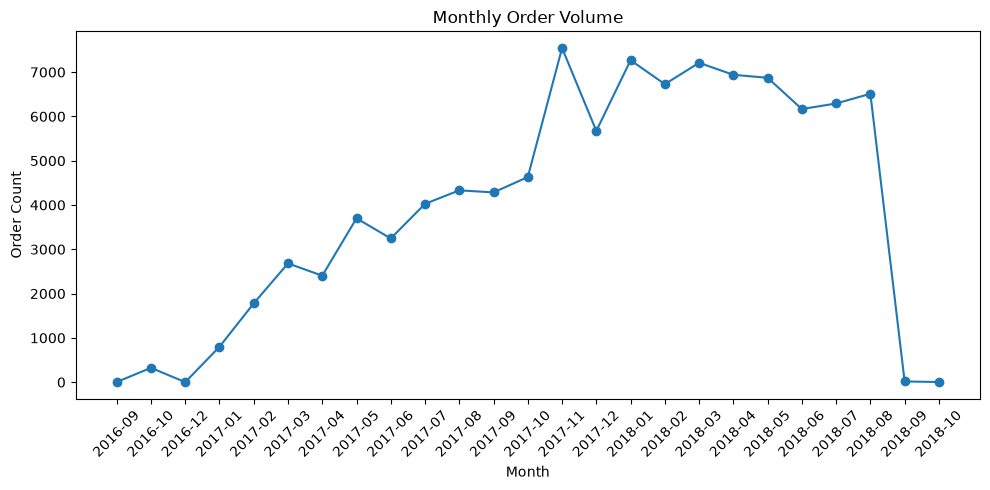

In [38]:
plt.figure(figsize=(10,5)) 

plt.plot(
    monthly_orders['month'].astype(str), #Matplotlib 对 Period 类型处理不好，所以转成字符串
    monthly_orders['order_count'], 
    marker='o'
) 

plt.xlabel('Month') 
plt.ylabel('Order Count') 

plt.title('Monthly Order Volume') 

plt.xticks(rotation=45) 

plt.tight_layout() 

# 保存图片到\reports\figures的地址

# 保存图片 
fig_dir = project_root.joinpath('reports', 'figures') 

fig_dir.mkdir(
    parents=True, 
    exist_ok=True 
)


plt.savefig(
    fig_dir.joinpath('monthly_orders.png'), 
    dpi=300, 
    bbox_inches='tight' 
)

plt.show() 

plt.close()


In [39]:
import numpy as np 

np.isclose(monthly_orders['order_count'].sum(), len(orders)) 

np.True_

### 构造延迟标签 

- `order_delivered_customer_date` & `order_estimated_delivery_date` 

- is_delayed in {0, 1} 

In [40]:
# 先检查有效订单数量，因为有些订单的时间是NaT 

orders[
    ['order_delivered_customer_date', 
     'order_estimated_delivery_date']
].isna().sum() 

order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [41]:
# 生成可以判断延迟的订单 

delay_mask = (
    orders['order_delivered_customer_date'].notna() 
    & orders['order_estimated_delivery_date'].notna() 
    & orders['order_approved_at'].notna() 
    & orders['order_status'].eq('delivered') 
) 

delay_orders = orders[delay_mask].copy() 
# .copy()：创建一份独立的数据副本，避免后续修改时出现 SettingWithCopyWarning 等问题
# df.loc[行选择条件, 列选择条件]

print(delay_orders.shape) 
print(orders.notna().sum()) 

(96456, 17)
order_id                         99441
customer_id                      99441
order_status                     99441
order_purchase_timestamp         99441
order_approved_at                99281
order_delivered_carrier_date     97658
order_delivered_customer_date    96476
order_estimated_delivery_date    99441
item_count                       98666
product_amount                   98666
freight_amount                   98666
total_amount                     98666
customer_unique_id               99441
customer_zip_code_prefix         99441
customer_city                    99441
customer_state                   99441
month                            99441
dtype: int64


In [42]:
delay_orders['is_delayed'] = (
    delay_orders['order_delivered_customer_date'].dt.normalize() 
    > 
    delay_orders['order_estimated_delivery_date'].dt.normalize()  
).astype(int) 
# 这里的预期送达时间都是00:00所以我需要将delivered变成00:00后再比较
# .dt.normalize() 会保留日期，并将时间统一设为 00:00:00

delay_orders['is_delayed'].value_counts() 

is_delayed
0    89922
1     6534
Name: count, dtype: int64

In [43]:
delay_rate = delay_orders['is_delayed'].mean() 

print(delay_rate) 

0.06774073152525503


In [44]:
# 太低了,所以需要验证写对了吗 

delay_orders[
    [
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].dtypes

order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [45]:
delay_orders[
    [
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "is_delayed"
    ]
][delay_orders['is_delayed']==1].head(10)

,order_delivered_customer_date,order_estimated_delivery_date,is_delayed
20,2017-10-09 22:23:46,2017-09-28,1
25,2018-03-21 22:03:54,2018-03-12,1
41,2017-12-28 18:59:23,2017-12-21,1
57,2018-04-03 13:28:46,2018-04-02,1
58,2017-04-06 13:37:16,2017-03-30,1
97,2017-12-28 19:43:00,2017-12-11,1
102,2018-08-03 19:28:47,2018-08-02,1
110,2018-01-23 21:38:52,2017-12-22,1
115,2018-01-20 13:42:22,2017-12-19,1
143,2018-03-22 00:03:53,2018-03-16,1


In [46]:
delay_rate = delay_orders['is_delayed'].mean() 

print(delay_rate*100) 

6.774073152525503


### 做延迟订单的初步分析 

In [47]:
delay_by_state = (
    delay_orders
    .groupby('customer_state')['is_delayed']
    .mean()
    .sort_values(ascending=False) 
) 
#把订单按照客户所在州分组，然后计算每个州的平均延迟标签（也就是延迟比例），最后按照延迟比例从高到低排序。
print(delay_by_state.head(10)) 


'''
SELECT
    customer_state,
    AVG(is_delayed) AS delay_rate
FROM delay_orders
GROUP BY customer_state
ORDER BY delay_rate DESC;
'''


customer_state
AL    0.214106
MA    0.174581
SE    0.152239
PI    0.138655
CE    0.137715
RR    0.121951
BA    0.121622
RJ    0.121072
PA    0.112051
ES    0.107268
Name: is_delayed, dtype: float64


'\nSELECT\n    customer_state,\n    AVG(is_delayed) AS delay_rate\nFROM delay_orders\nGROUP BY customer_state\nORDER BY delay_rate DESC;\n'

### 分析订单金额和延迟关系 

In [48]:
amount_by_delay =  (
    delay_orders
    .groupby('is_delayed')['total_amount'] 
    .describe()
)

amount_by_delay 

,count,mean,std,min,25%,50%,75%,max
is_delayed,,,,,,,,
0,89922.0,158.643581,217.076494,9.59,61.5900,104.590,175.3575,13664.08
1,6534.0,176.138985,240.888921,14.29,67.5075,114.095,190.5700,6922.21


In [49]:
delay_orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'item_count', 'product_amount', 'freight_amount', 'total_amount',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'month', 'is_delayed'],
      dtype='str')

In [50]:
state_summary = (
    delay_orders.groupby('customer_state')
    .agg(
        order_count=('order_id', 'count'), 
        delay_rate=('is_delayed', 'mean') 
    )
    .sort_values(
        'delay_rate', 
        ascending=False 
    )
) 

state_summary.head(10) 

print(state_summary.index) 
print(state_summary.columns)

# 由于state是现在表格的index，需要将其变为colummn

state_summary = state_summary.reset_index()

Index(['AL', 'MA', 'SE', 'PI', 'CE', 'RR', 'BA', 'RJ', 'PA', 'ES', 'PB', 'TO',
       'MS', 'PE', 'RN', 'SC', 'GO', 'RS', 'MT', 'DF', 'MG', 'SP', 'PR', 'AC',
       'AP', 'RO', 'AM'],
      dtype='str', name='customer_state')
Index(['order_count', 'delay_rate'], dtype='str')


In [51]:
state_summary = state_summary[
    state_summary['order_count'] > 1000
].sort_values(
    'delay_rate', 
    ascending=False 
)

state_summary

reports_path = project_root.joinpath('reports') 

state_summary.to_csv(
    reports_path.joinpath('state_delay_summary.csv'), 
    index=False 
) 

amount_by_delay.to_csv(
    reports_path.joinpath('amount_delay_summary.csv')
)


delay_orders.to_csv(
    processed_path.joinpath('orders_with_delay.csv'), 
    index=False 
)


# 第 5 天：订单延迟探索性分析（EDA）

本阶段基于订单级数据集 `orders_full` 开展探索性数据分析（Exploratory Data Analysis, EDA）。

主要分析内容包括：

1. 月度订单量变化趋势；
2. 订单延迟标签构造；
3. 整体订单延迟情况分析；
4. 地区因素与订单延迟关系；
5. 订单金额与延迟关系分析。

通过 EDA 了解订单配送情况及潜在影响因素，为后续特征工程和预测模型构建提供基础。

---

# 1. 月度订单量变化分析

## 分析目的

为了了解平台订单规模随时间的变化情况，根据订单创建时间统计不同月份的订单数量。

## 分析字段

使用字段：

- `order_purchase_timestamp`

提取月份：

- `month`

统计指标：

- 每月订单数量（order_count）

---

## 分析方法

按照月份进行分组：

- 统计每个月订单数量；
- 使用折线图展示订单量变化趋势。

结果保存：

```
reports/figures/monthly_orders.png
```

---

## 分析结论

月度订单量分析结果显示：

1. 平台订单量在不同月份存在明显变化；
2. 随着时间推移，整体订单规模呈增长趋势；
3. 订单量变化能够反映平台业务发展情况，可作为后续时间特征的重要参考。

---

# 2. 订单延迟标签构造

## 2.1 延迟定义

为了预测订单配送风险，需要构造订单是否延迟的目标变量：

`is_delayed`

定义规则：

\[
is\_delayed=
\begin{cases}
1, & 实际送达时间 > 预计送达时间\\
0, & 实际送达时间 \leq 预计送达时间
\end{cases}
\]

其中：

实际送达时间：

```
order_delivered_customer_date
```

预计送达时间：

```
order_estimated_delivery_date
```

---

## 2.2 数据筛选

由于部分订单不存在实际送达时间，无法判断是否延迟，因此仅保留：

- 实际送达时间存在；
- 预计送达时间存在；

的有效订单进行分析。

有效订单数量：

```
96476
```

---

# 3. 整体订单延迟情况分析

## 延迟订单统计

统计结果：

| 是否延迟 | 订单数量 |
| --- | ---: |
| 未延迟（0） | 88649 |
| 延迟（1） | 7827 |

---

## 延迟比例

整体订单延迟率：

```
8.11%
```

计算方式：

\[
delay\_rate=
\frac{延迟订单数量}{有效订单数量}
\]

即：

\[
\frac{7827}{96476}=8.11\%
\]

---

## 分析结论

结果显示：

1. 大部分订单能够在预计时间内完成配送；
2. 仍有约 8.11% 的订单发生配送延迟；
3. `is_delayed` 可以作为后续预测模型的目标变量。

---

# 4. 地区与订单延迟关系分析

## 分析目的

探索不同客户所在地区是否存在配送延迟差异。

分析字段：

- `customer_state`
- `is_delayed`

统计指标：

### 订单数量

表示该地区有效订单规模：

```
order_count
```

### 延迟率

表示该地区订单延迟比例：

\[
delay\_rate=
\frac{延迟订单数量}{订单数量}
\]

---

## 分析方法

按照客户所在州进行分组：

- 统计订单数量；
- 计算平均延迟标签；
- 得到各州延迟率。

为了减少小样本地区造成的随机波动，仅保留：

```
订单数量 > 1000
```

的地区进行比较。

结果保存：

```
reports/state_delay_summary.csv
```

---

## 分析结论

地区分析结果显示：

1. 不同州之间订单延迟率存在一定差异；
2. 地区因素可能影响配送效率；
3. 客户所在地区可以作为后续预测模型中的候选特征。

---

# 5. 订单金额与延迟关系分析

## 分析目的

探索订单金额是否与订单延迟存在统计关系。

分析字段：

- `total_amount`
- `is_delayed`

---

## 分析方法

按照订单是否延迟进行分组：

```python
groupby("is_delayed")
```

统计：

- 平均金额；
- 中位数；
- 标准差；
- 最大值等。

结果保存：

```
reports/amount_delay_summary.csv
```

---

## 分析结论

分析结果显示：

1. 延迟订单与未延迟订单在订单金额分布上存在差异；
2. 延迟订单金额分布更加分散；
3. 订单金额可能与配送延迟存在一定关联。

需要注意：

订单金额与延迟之间只能说明统计关联，不能说明订单金额直接导致配送延迟。

后续模型阶段可以将订单金额相关字段作为候选输入特征。

---

# 6. 数据保存

本阶段生成的数据和分析结果：

## 订单延迟数据

路径：

```
data/processed/orders_with_delay.csv
```

该数据包含：

- 订单信息；
- 商品聚合信息；
- 客户地区信息；
- 延迟标签 `is_delayed`。

用于后续：

- 特征工程；
- 模型训练。


---

## 分析结果文件

```
reports/
│
├── figures/
│   └── monthly_orders.png
│
├── state_delay_summary.csv
│
└── amount_delay_summary.csv
```

---

# 总结

本阶段完成订单延迟相关的探索性分析：

1. 分析订单量随时间变化趋势；
2. 基于实际送达时间和预计送达时间构造延迟标签；
3. 计算整体订单延迟比例；
4. 分析地区因素与延迟之间的关系；
5. 分析订单金额与延迟之间的关系。

通过 EDA，对订单配送情况及潜在影响因素进行了初步了解，为下一阶段特征工程和预测模型构建提供基础。